# scATAC cell-type classification (Figure 3a-e)

Reads tables from `../data/` and writes figures to `../output/`. Source notebook is listed in `../../NOTEBOOK_PROVENANCE.tsv`.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from this notebook's folder (nbconvert default),
# from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA)
print("OUT :", OUT)


DATA: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/data
OUT : /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output


saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output/scatac_auc_ranked.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output/scatac_auc_ranked.png


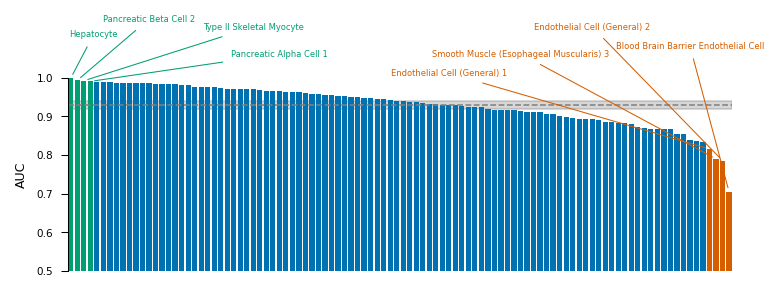

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Liberation Sans', 'Arial', 'Helvetica'],
    'font.size': 6,
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 5,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'figure.dpi': 150,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
})

from scipy.stats import bootstrap

plt.rcParams.update({'font.size': 6, 'axes.labelsize': 6, 'xtick.labelsize': 5, 'ytick.labelsize': 5})
metrics_df = pd.read_csv(DATA / 'scatac_task_metrics.csv')
df_plot = metrics_df.sort_values('auc', ascending=False).reset_index(drop=True)
top4 = df_plot.head(4)['case_label'].tolist()
bottom4 = df_plot.tail(4)['case_label'].tolist()
n = len(df_plot)
colors = ['#009E73' if ct in top4 else '#D55E00' if ct in bottom4 else '#0072B2' for ct in df_plot['case_label']]
fig, ax = plt.subplots(figsize=(5.2, 2))
x = np.arange(n)
ax.bar(x, df_plot['auc'], color=colors, width=0.8, edgecolor='none')
auc_vals = df_plot['auc'].values
mean_result = bootstrap((auc_vals,), np.mean, n_resamples=10000, confidence_level=0.95, method='BCa', random_state=np.random.default_rng(42))
grand_mean = auc_vals.mean(); mean_ci_low, mean_ci_high = mean_result.confidence_interval
ax.axhspan(mean_ci_low, mean_ci_high, color='gray', alpha=0.3, zorder=0)
ax.axhline(grand_mean, color='gray', lw=0.75, ls='--')
for i, x_text, y_text in zip(df_plot.head(4).index.tolist(), [3.5, 12, 28, 32], [1.1, 1.14, 1.12, 1.05]):
    row = df_plot.iloc[i]
    ax.annotate(row['case_label'], xy=(i, row['auc']), xytext=(x_text, y_text), fontsize=4, va='bottom', ha='center', color='#009E73', arrowprops=dict(arrowstyle='-', color='#009E73', lw=0.5), clip_on=False, annotation_clip=False)
for i, x_text, y_text in zip(df_plot.tail(4).index.tolist(), [n - 44, n - 33, n - 22, n - 7], [1, 1.05, 1.12, 1.07]):
    row = df_plot.iloc[i]
    ax.annotate(row['case_label'], xy=(i, row['auc']), xytext=(x_text, y_text), fontsize=4, va='bottom', ha='center', color='#D55E00', arrowprops=dict(arrowstyle='-', color='#D55E00', lw=0.5), clip_on=False, annotation_clip=False)
ax.set_xlim(-0.5, n - 0.5); ax.set_ylim(0.5, 1.0); ax.set_xticks([]); ax.set_ylabel('AUC', fontsize=6)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False); ax.spines['bottom'].set_visible(False)
plt.tight_layout(); savefig(fig, OUT, 'scatac_auc_ranked')

saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output/scatac_auc_distribution_ap_lift.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output/scatac_auc_distribution_ap_lift.png


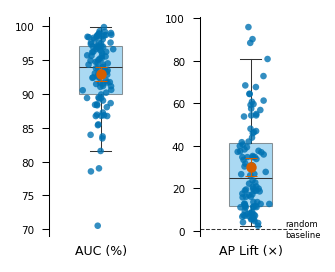

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Liberation Sans', 'Arial', 'Helvetica'],
    'font.size': 6,
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 5,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'figure.dpi': 150,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
})


metrics_df = pd.read_csv(DATA / 'scatac_task_metrics.csv')
fig, axes = plt.subplots(1, 2, figsize=(2.2, 1.8))
auc_pct = metrics_df['auc'] * 100
ap_lift = metrics_df['ap_lift_mult']
dot_color = '#0072B2'; box_color = '#56B4E9'; mean_color = '#D55E00'
np.random.seed(42)
for ax, data, xlabel, baseline in zip(axes, [auc_pct, ap_lift], ['AUC (%)', 'AP Lift (×)'], [None, 1]):
    ax.boxplot([data], positions=[1], widths=0.5, patch_artist=True,
               boxprops=dict(facecolor=box_color, alpha=0.5, edgecolor='#333', linewidth=0.5),
               medianprops=dict(color='#333', linewidth=0.5), whiskerprops=dict(color='#333', linewidth=0.5),
               capprops=dict(color='#333', linewidth=0.5), flierprops=dict(marker='none'))
    jitter = np.random.normal(0, 0.08, len(data))
    ax.scatter(1 + jitter, data, c=dot_color, s=10, alpha=0.8, edgecolors='none', zorder=3, rasterized=True)
    mean_val = data.mean(); ci_95 = 1.96 * data.std() / np.sqrt(len(data))
    ax.errorbar(1, mean_val, yerr=ci_95, fmt='o', color=mean_color, markersize=4, capsize=3, capthick=0.5, linewidth=0.5, zorder=5)
    if baseline is not None:
        ax.axhline(baseline, color='black', ls='--', lw=0.5, alpha=0.8)
        ax.text(1.4, baseline, 'random\nbaseline', fontsize=4, va='center')
    ax.set_xticks([]); ax.set_xlabel(xlabel, fontsize=6); ax.set_xlim(0.4, 1.6)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False); ax.spines['bottom'].set_visible(False)
plt.tight_layout(); savefig(fig, OUT, 'scatac_auc_distribution_ap_lift')

/home/hamedh/bin/miniforge3/envs/bch/lib/python3.10/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output/scatac_umap.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output/scatac_umap.png


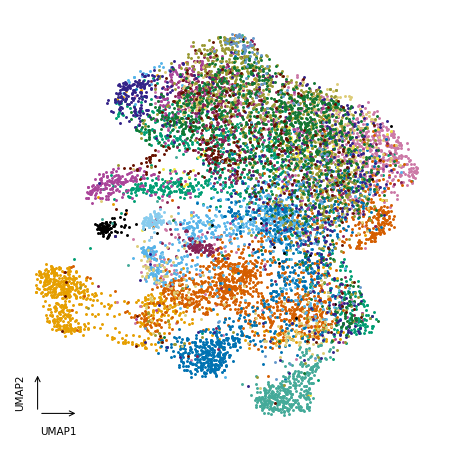

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Liberation Sans', 'Arial', 'Helvetica'],
    'font.size': 6,
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 5,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'figure.dpi': 150,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
})

from sklearn.preprocessing import StandardScaler
from umap import UMAP


CELL_TYPE_CATEGORIES = {
    'Atrial Cardiomyocyte': 'Cardiac', 'Ventricular Cardiomyocyte': 'Cardiac',
    'Cardiac Fibroblasts': 'Cardiac', 'Cardiac Pericyte 1': 'Cardiac',
    'Cardiac Pericyte 2': 'Cardiac', 'Cardiac Pericyte 3': 'Cardiac',
    'Cardiac Pericyte 4': 'Cardiac', 'Endocardial Cell': 'Cardiac',
    'Endothelial Cell (Myocardial)': 'Cardiac',
    'Pancreatic Alpha Cell 1': 'Pancreatic', 'Pancreatic Alpha Cell 2': 'Pancreatic',
    'Pancreatic Beta Cell 1': 'Pancreatic', 'Pancreatic Beta Cell 2': 'Pancreatic',
    'Pancreatic Delta,Gamma cell': 'Pancreatic', 'Pancreatic Acinar Cell': 'Pancreatic',
    'Ductal Cell (Pancreatic)': 'Pancreatic',
    'Keratinocyte 1': 'Skin', 'Keratinocyte 2': 'Skin', 'Basal Epidermal (Skin)': 'Skin',
    'Granular Epidermal (Skin)': 'Skin', 'Eccrine Epidermal (Skin)': 'Skin',
    'Melanocyte': 'Skin', 'Myoepithelial (Skin)': 'Skin',
    'Colon Epithelial Cell 1': 'Gastrointestinal', 'Colon Epithelial Cell 2': 'Gastrointestinal',
    'Colon Epithelial Cell 3': 'Gastrointestinal', 'Colonic Goblet Cell': 'Gastrointestinal',
    'Small Intestinal Enterocyte': 'Gastrointestinal', 'Small Intestinal Goblet Cell': 'Gastrointestinal',
    'Foveolar Cell': 'Gastrointestinal', 'Chief Cell': 'Gastrointestinal', 'Parietal Cell': 'Gastrointestinal',
    'Enterochromaffin Cell': 'Gastrointestinal', 'Gastric Neuroendocrine Cell': 'Gastrointestinal',
    'Paneth Cell': 'Gastrointestinal', 'Tuft Cell': 'Gastrointestinal',
    'Alveolar Type 1 (AT1) Cell': 'Respiratory', 'Alveolar Type 2 (AT2) Cell': 'Respiratory',
    'Alverolar Type 2,Immune': 'Respiratory', 'Alveolar Capillary Endothelial Cell': 'Respiratory',
    'Airway Goblet Cell': 'Respiratory', 'Club Cell': 'Respiratory', 'Cilliated Cell': 'Respiratory',
    'Esophageal Epithelial Cell': 'Esophageal', 'Smooth Muscle (Esophageal Mucosal)': 'Esophageal',
    'Smooth Muscle (Esophageal Muscularis) 1': 'Esophageal',
    'Smooth Muscle (Esophageal Muscularis) 2': 'Esophageal',
    'Smooth Muscle (Esophageal Muscularis) 3': 'Esophageal',
    'Pericyte (Esophageal Muscularis)': 'Esophageal',
    'Type I Skeletal Myocyte': 'Skeletal Muscle', 'Type II Skeletal Myocyte': 'Skeletal Muscle',
    'Satellite Cell': 'Skeletal Muscle', 'Fibroblast (Sk Muscle Associated)': 'Skeletal Muscle',
    'Mammary Epithelial': 'Mammary', 'Mammary Luminal Epithelial Cell 1': 'Mammary',
    'Mammary Luminal Epithelial Cell 2': 'Mammary', 'Basal Epithelial (Mammary)': 'Mammary',
    'Hepatocyte': 'Liver', 'Thyroid Follicular Cell': 'Thyroid',
    'Zona Fasciculata Cortical Cell': 'Adrenal', 'Zona Glomerulosa Cortical Cell': 'Adrenal',
    'Transitional Zone Cortical Cell': 'Adrenal', 'Cortical Epithelial-like': 'Adrenal',
    'Memory B Cell': 'Immune', 'Naive T cell': 'Immune', 'Natural Killer T Cell': 'Immune',
    'T Lymphocyte 1 (CD8+)': 'Immune', 'T lymphocyte 2 (CD4+)': 'Immune',
    'Plasma Cell': 'Immune', 'Mast Cell': 'Immune', 'Macrophage (General)': 'Immune',
    'Macrophage (General,Alveolar)': 'Immune',
    'Smooth Muscle (General)': 'Smooth Muscle', 'Smooth Muscle (General Gastrointestinal)': 'Smooth Muscle',
    'Smooth Muscle (Colon) 1': 'Smooth Muscle', 'Smooth Muscle (Colon) 2': 'Smooth Muscle',
    'Smooth Muscle (GE Junction)': 'Smooth Muscle', 'Smooth Muscle (Uterine)': 'Smooth Muscle',
    'Smooth Muscle (Vaginal)': 'Smooth Muscle', 'Vascular Smooth Muscle 1': 'Smooth Muscle',
    'Vascular Smooth Muscle 2': 'Smooth Muscle',
    'Endothelial Cell (General) 1': 'Endothelial', 'Endothelial Cell (General) 2': 'Endothelial',
    'Endothelial Cell (General) 3': 'Endothelial', 'Lymphatic Endothelial Cell': 'Endothelial',
    'Blood Brain Barrier Endothelial Cell': 'Endothelial', 'Endothelial (Exocrine Tissues)': 'Endothelial',
    'Fibroblast (General)': 'Stromal', 'Fibroblast (Epithelial)': 'Stromal',
    'Fibroblast (Gastrointestinal)': 'Stromal', 'Fibroblast (Liver Adrenal)': 'Stromal',
    'Fibroblast (Peripheral Nerve)': 'Stromal', 'Pericyte (General) 1': 'Stromal',
    'Pericyte (General) 2': 'Stromal', 'Pericyte (General) 3': 'Stromal',
    'Pericyte (General) 4': 'Stromal', 'Mesothelial Cell': 'Stromal',
    'CNS,Enteric Neuron': 'Neural', 'Schwann Cell (General)': 'Neural',
    'Peripheral Nerve Stromal': 'Neural',
    'Adipocyte': 'Adipose', 'Luteal Cell (Ovarian)': 'Reproductive',
}
CATEGORY_COLORS = {
    'Cardiac': '#009E73', 'Pancreatic': '#E69F00', 'Skin': '#CC79A7',
    'Gastrointestinal': '#D55E00', 'Respiratory': '#56B4E9', 'Immune': '#0072B2',
    'Liver': '#000000', 'Adipose': '#F0E442', 'Esophageal': '#882255',
    'Skeletal Muscle': '#AA4499', 'Mammary': '#DDCC77', 'Thyroid': '#88CCEE',
    'Adrenal': '#44AA99', 'Smooth Muscle': '#999933', 'Endothelial': '#332288',
    'Stromal': '#117733', 'Neural': '#661100', 'Reproductive': '#6699CC',
}

prob_matrix = pd.read_csv(DATA / 'scatac_probability_matrix.csv')
metadata = pd.read_csv(DATA / 'scatac_metadata_minimal.csv')
if 'sample_id' in prob_matrix.columns:
    prob_matrix = prob_matrix.set_index('sample_id')
sample_to_celltype = dict(zip(metadata['sample_id'], metadata['group']))
prob_matrix['true_celltype'] = prob_matrix.index.map(sample_to_celltype)
prob_matrix['category'] = prob_matrix['true_celltype'].map(CELL_TYPE_CATEGORIES).fillna('Other')
task_cols = [c for c in prob_matrix.columns if c not in {'true_celltype', 'category', 'umap1', 'umap2'}]
X = prob_matrix[task_cols].to_numpy(dtype=float)
eps = 1e-5
X = np.clip(X, eps, 1 - eps)
X = np.log(X / (1 - X))
X = StandardScaler().fit_transform(X)
emb = UMAP(n_neighbors=15, min_dist=0.5, spread=1.0, metric='cosine', random_state=42).fit_transform(X)
prob_matrix['umap1'], prob_matrix['umap2'] = emb[:, 0], emb[:, 1]
prob_matrix[['umap1', 'umap2', 'true_celltype', 'category']].to_csv(OUT / 'scatac_umap_coords.csv')
fig, ax = plt.subplots(figsize=(3, 3))
for cat in CATEGORY_COLORS:
    mask = prob_matrix['category'] == cat
    if mask.sum() > 0:
        ax.scatter(prob_matrix.loc[mask, 'umap1'], prob_matrix.loc[mask, 'umap2'], s=2, alpha=1.0, c=CATEGORY_COLORS[cat], label=cat, linewidth=0, rasterized=True)
ax.set_xticks([]); ax.set_yticks([])
for sp in ax.spines.values(): sp.set_visible(False)
xlim, ylim = ax.get_xlim(), ax.get_ylim()
arrow_len_x = (xlim[1] - xlim[0]) * 0.10; arrow_len_y = (ylim[1] - ylim[0]) * 0.10
arrow_x = xlim[0] + (xlim[1] - xlim[0]) * 0.05; arrow_y = ylim[0] + (ylim[1] - ylim[0]) * 0.05
ax.annotate('', xy=(arrow_x + arrow_len_x, arrow_y), xytext=(arrow_x, arrow_y), arrowprops=dict(arrowstyle='->', color='black', lw=0.5))
ax.text(arrow_x + arrow_len_x/2, arrow_y - (ylim[1]-ylim[0])*0.03, 'UMAP1', ha='center', va='top', fontsize=5)
ax.annotate('', xy=(arrow_x, arrow_y + arrow_len_y), xytext=(arrow_x, arrow_y), arrowprops=dict(arrowstyle='->', color='black', lw=0.5))
ax.text(arrow_x - (xlim[1]-xlim[0])*0.03, arrow_y + arrow_len_y/2, 'UMAP2', ha='right', va='center', fontsize=5, rotation=90)
plt.tight_layout(); savefig(fig, OUT, 'scatac_umap')

saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output/scatac_leaf1_vs_coordinate_binning.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output/scatac_leaf1_vs_coordinate_binning.png


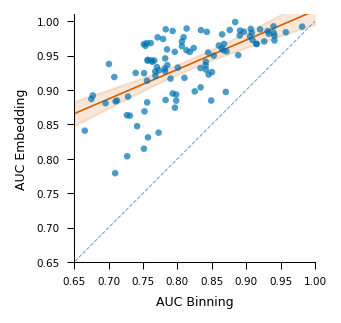

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Liberation Sans', 'Arial', 'Helvetica'],
    'font.size': 6,
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 5,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'figure.dpi': 150,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
})

from scipy.stats import pearsonr, t as t_dist


from scipy.stats import pearsonr
from scipy.stats import t as t_dist

kfold_df = pd.read_csv(DATA / 'scatac_coordinate_binning_auc_by_fold.csv')
mean_auc = kfold_df.groupby(['Target', 'Method'])['AUC'].mean().unstack('Method')
x = mean_auc['Bin 100k'].values
y = mean_auc['Embedding'].values
r, r_pval = pearsonr(x, y)

fig, ax = plt.subplots(figsize=(2.2, 2.2))
ax.scatter(x, y, c=OKABE_ITO['blue'], s=10, alpha=0.7, edgecolors='none', zorder=3, rasterized=True)
lims = [min(x.min(), y.min()) - 0.02, max(x.max(), y.max()) + 0.02]
ax.plot(lims, lims, ls='--', color=OKABE_ITO['blue'], lw=0.5, alpha=0.6, zorder=1)
m, b = np.polyfit(x, y, 1)
x_fit = np.linspace(lims[0], lims[1], 200)
y_fit = m * x_fit + b
n_pts = len(x)
x_mean = x.mean()
residuals = y - (m * x + b)
s_err = np.sqrt(np.sum(residuals**2) / (n_pts - 2))
t_crit = t_dist.ppf(0.975, n_pts - 2)
se_fit = s_err * np.sqrt(1/n_pts + (x_fit - x_mean)**2 / np.sum((x - x_mean)**2))
ci_upper = y_fit + t_crit * se_fit
ci_lower = y_fit - t_crit * se_fit
ax.plot(x_fit, y_fit, color=OKABE_ITO['vermillion'], lw=0.8, zorder=2)
ax.fill_between(x_fit, ci_lower, ci_upper, color=OKABE_ITO['vermillion'], alpha=0.15, zorder=1)
ax.set_xlabel('AUC Binning', fontsize=6)
ax.set_ylabel('AUC Embedding', fontsize=6)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect('equal')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylim(0.65,1.01)
ax.set_xlim(0.65,1)
plt.tight_layout(); savefig(fig, OUT, 'scatac_leaf1_vs_coordinate_binning')


saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output/scatac_ccre_fragment_scores.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf1-paper-reproducibility/leaf-1-figures/scatac/output/scatac_ccre_fragment_scores.png


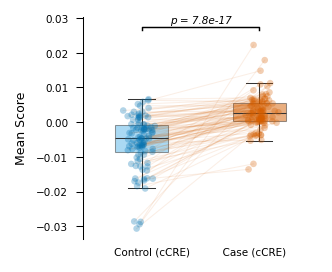

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Exact-source rcParams for this panel family.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Liberation Sans', 'Arial', 'Helvetica'],
    'font.size': 6,
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 5,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'figure.dpi': 150,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
})

from scipy.stats import ttest_rel

stats_df = pd.read_csv(DATA / 'scatac_ccre_comprehensive_statistics.csv')
ccre = stats_df[(stats_df['Region'] == 'In cCREs') & (stats_df['Condition'].isin(['Case', 'Control']))]
pivot = ccre.pivot(index='Model', columns='Condition', values='Mean').dropna()
control_vals = pivot['Control'].values; case_vals = pivot['Case'].values
stat, pval = ttest_rel(case_vals, control_vals)
fig, ax = plt.subplots(figsize=(2.2, 1.8))
for cond, pos, bfill in zip(['Control', 'Case'], [0, 1], [OKABE_ITO['sky'], OKABE_ITO['vermillion']]):
    vals = pivot[cond].values
    ax.boxplot([vals], positions=[pos], widths=0.45, patch_artist=True,
               boxprops=dict(facecolor=bfill, alpha=0.5, edgecolor='#333', linewidth=0.5),
               medianprops=dict(color='#333', linewidth=0.5), whiskerprops=dict(color='#333', linewidth=0.5),
               capprops=dict(color='#333', linewidth=0.5), flierprops=dict(marker='none'))
np.random.seed(42)
jitter_ctrl = np.random.normal(0, 0.06, len(control_vals)); jitter_case = np.random.normal(0, 0.06, len(case_vals))
x_ctrl = jitter_ctrl; x_case = 1 + jitter_case
for xc, xk, yc, yk in zip(x_ctrl, x_case, control_vals, case_vals):
    ax.plot([xc, xk], [yc, yk], color=OKABE_ITO['vermillion'], alpha=0.1, linewidth=0.5, zorder=2)
ax.scatter(x_ctrl, control_vals, c=OKABE_ITO['blue'], s=10, alpha=0.3, edgecolors='none', zorder=3, rasterized=True)
ax.scatter(x_case, case_vals, c=OKABE_ITO['vermillion'], s=10, alpha=0.3, edgecolors='none', zorder=3, rasterized=True)
y_max = max(control_vals.max(), case_vals.max()); y_min = min(control_vals.min(), case_vals.min())
bracket_y = y_max + (y_max - y_min) * 0.08
ax.plot([0, 0, 1, 1], [bracket_y, bracket_y + 0.001, bracket_y + 0.001, bracket_y], color='black', linewidth=0.7)
ax.text(0.5, bracket_y + 0.0015, f'p = {pval:.1e}', ha='center', va='bottom', fontsize=5, fontstyle='italic')
ax.set_xticks([]); ax.set_xlabel('Control (cCRE)          Case (cCRE)', fontsize=5); ax.set_ylabel('Mean Score', fontsize=6); ax.set_xlim(-0.5, 1.5)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False); ax.spines['bottom'].set_visible(False)
plt.tight_layout(); savefig(fig, OUT, 'scatac_ccre_fragment_scores')